#CLIMATE RISK AND HEALTH PREDICTION


##Problem Statement
**What we are trying to predict**: We are trying to predict whether a death is climate-sensitive or not, a climate-sensitive death is one that is linked to climate or weather conditions. A death that is not climate-sensitive is not linked to them.1 means climate-sensitive and 0 means not climate-sensitive.

**Information used for the prediction**: Details about the person ( Gender, Age), details about when and where the death occurred(Deathdate,Zone(rural or peri-urban), latitude, longitude and location ), and the weather conditions recorded( Average,Maximum,Minimum temperature, precipitation (rainfall))

**Why it matters**: This matters because Planners, health officials, government health agencies and organisations working on climate and health can use a model that predicts whether a death is climate-sensitive. They can prepare health facilities, send medical supplies and issue warnings before hot or heavy-rain periods so that illness and deaths will be reduced.

In [32]:
import pandas as pd

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:

train = pd.read_csv("/content/drive/MyDrive/Group195_Data/Climate_Train (1).csv")
test = pd.read_csv("/content/drive/MyDrive/Group195_Data/Climate_Test.csv")

In [35]:
train.shape

(3146, 13)

In [36]:
train.head(5)

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


In [37]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), object(5)
memory usage: 319.6+ KB


In [38]:
train.isnull().sum()

,0
ID,0
zone,0
gender,0
deathdate,0
age,0
avg_temperature,0
max_temperature,0
min_temperature,0
precipitation,0
latitude,0


In [39]:
train.columns

Index(['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature',
       'max_temperature', 'min_temperature', 'precipitation', 'latitude',
       'longitude', 'location', 'is_climate_sensitive'],
      dtype='object')

In [40]:
print(train.duplicated().sum())

0


In [41]:
train["is_climate_sensitive"].value_counts()

,count
is_climate_sensitive,
1,2047
0,1099


In [42]:
test.shape

(1030, 12)

In [43]:
test.head(5)

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location
0,ID_E760D84B,Rural,Female,2007-11-24,75.0,21.224387,24.632729,18.145633,4.295335,0.616667,33.500000,"Buseyi, Iganga, Uganda"
1,ID_6EDEA907,Rural,Female,2008-01-23,50.0,21.708596,25.184528,18.285274,1.376196,0.725422,33.098845,"Bubago, Kamuli, Uganda"
2,ID_B9FFC8D8,Rural,Female,2008-03-14,76.0,21.371149,24.584523,18.866490,2.336643,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"
3,ID_74C6C94E,Peri_urban,Female,2008-04-16,90.0,21.341990,25.188662,17.998317,4.703071,-0.590211,30.056939,"Kayanga, Mitooma, Western Region, Uganda"
4,ID_0E02825D,Rural,Male,2008-04-21,8.0,19.710391,22.905167,18.082628,4.066863,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"


In [44]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               1030 non-null   object 
 1   zone             1030 non-null   object 
 2   gender           1030 non-null   object 
 3   deathdate        1030 non-null   object 
 4   age              1030 non-null   float64
 5   avg_temperature  1030 non-null   float64
 6   max_temperature  1030 non-null   float64
 7   min_temperature  1030 non-null   float64
 8   precipitation    1030 non-null   float64
 9   latitude         1030 non-null   float64
 10  longitude        1030 non-null   float64
 11  location         1030 non-null   object 
dtypes: float64(7), object(5)
memory usage: 96.7+ KB


In [45]:
test.columns

Index(['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature',
       'max_temperature', 'min_temperature', 'precipitation', 'latitude',
       'longitude', 'location'],
      dtype='object')

In [46]:
test.isnull().sum()

,0
ID,0
zone,0
gender,0
deathdate,0
age,0
avg_temperature,0
max_temperature,0
min_temperature,0
precipitation,0
latitude,0


In [47]:
print(test.duplicated().sum())

0


#Observation on both data

1. Train data has 3146 rows and 13 columns while Test data has 1030 rows and 12 Columns.

2. is_climate_sensitive Column is in train data but not in test data because it is the target,so the model has to predict it for the test records but the other 12 Columns have the same names in both files.

3. no missing value in both data

4. no duplicate in both data

5. Class 1 (climate-sensitive) has 2,047 records and Class 0 (not climate-sensitive) has 1,099 records. The two classes are not the same size. Class 1 is almost twice as big as class 0, This shows that the data is imbalanced. 65% for class 1 and 35% for class 0. a model that always guessed class 1 would be right about 65% of the time, so accuracy alone is not a good measure, and we will also use ROC-AUC, precision and recall

##DATA VISUALISATION (EXPLORATORY ANALYSIS)
This section use charts to see how the features relate to is_climate_sensitive

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

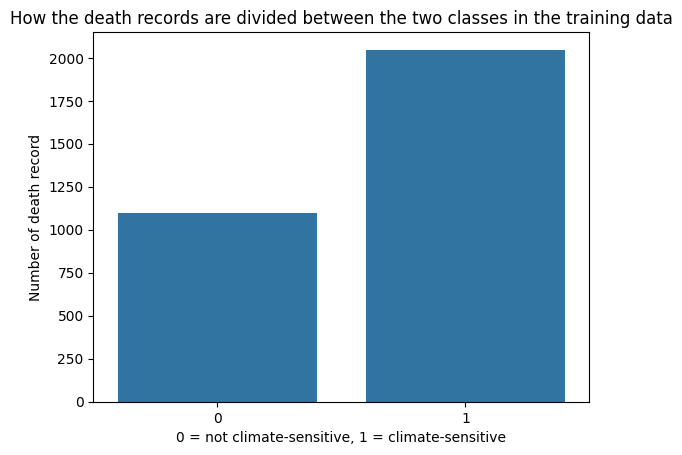

In [49]:
sns.countplot(data=train,x="is_climate_sensitive")
plt.title("How the death records are divided between the two classes in the training data")
plt.xlabel("0 = not climate-sensitive, 1 = climate-sensitive")
plt.ylabel("Number of death record")
plt.show()

The chart above shows that climate-sensitive has more records than the not climate-sensitive, the climate-sensitive is almost twice as many more than the not climate-sensitive. About 65% of records are climate-sensitive and 35% are not which shows that the classes are imbalanced.

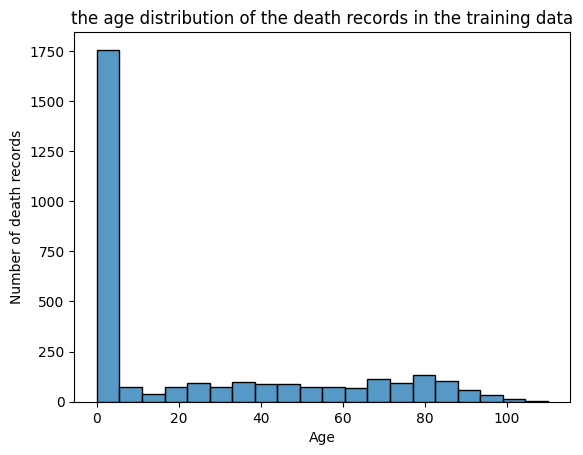

In [50]:

sns.histplot(data=train, x="age", bins=20)
plt.title("the age distribution of the death records in the training data")
plt.xlabel("Age")
plt.ylabel("Number of death records")
plt.show()

Most of the death records are of youngchildern aged 0 to 5 years the number of records is low and spread across the older ages.

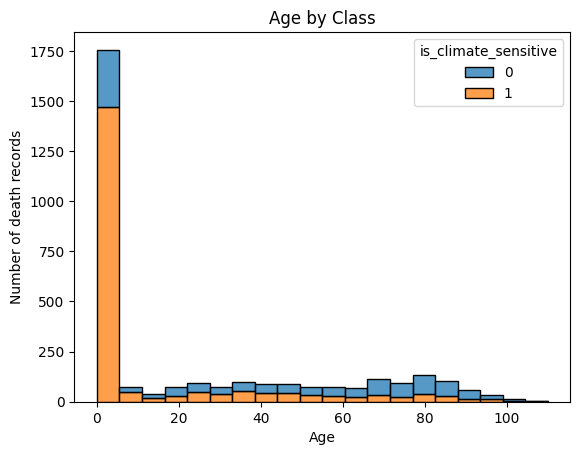

In [51]:
sns.histplot(data=train, x="age", bins=20, hue="is_climate_sensitive", multiple="stack")
plt.title("Age by Class")
plt.xlabel("Age")
plt.ylabel("Number of death records")
plt.show()

In the age group 0 to 5, the climate-sensitive class is much larger.In the older ages, the not climate-sensitive class is larger than the other

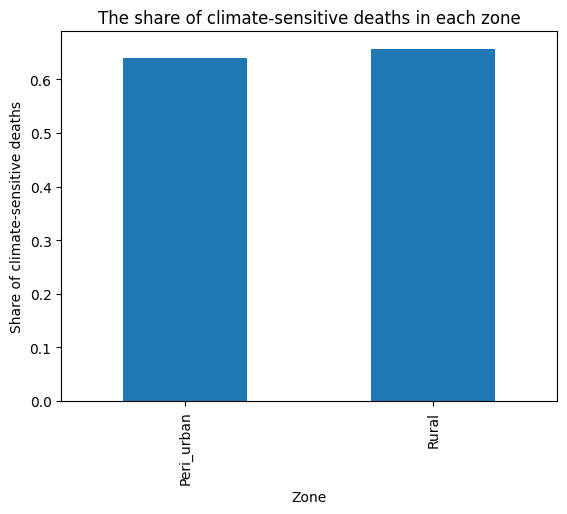

In [52]:
train.groupby("zone")["is_climate_sensitive"].mean().plot(kind="bar")
plt.title("The share of climate-sensitive deaths in each zone")
plt.xlabel("Zone")
plt.ylabel("Share of climate-sensitive deaths")
plt.show()

The share of climate-sensitive deaths is similar in the two zones, about 64% in the peri-urban zone and about 66% in the rural zone

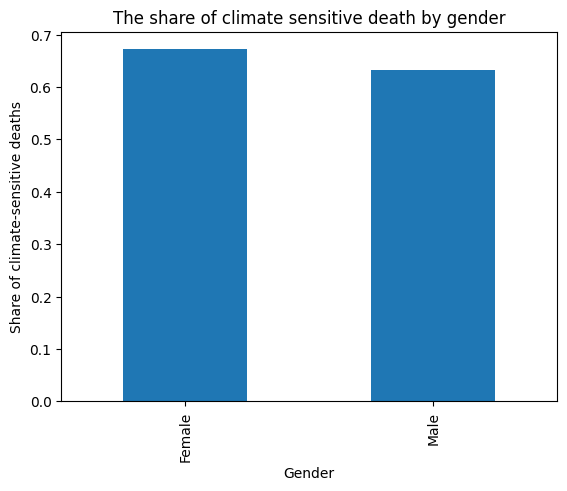

In [53]:
train.groupby("gender")["is_climate_sensitive"].mean().plot(kind="bar")
plt.title("The share of climate sensitive death by gender")
plt.xlabel("Gender")
plt.ylabel("Share of climate-sensitive deaths")
plt.show()

The share of climate-sensitive deaths is similar for females and males

In [54]:
train.groupby("gender")["is_climate_sensitive"].mean()

,is_climate_sensitive
gender,
Female,0.671552
Male,0.631611


This shows that the share of climate sensitive death is similar to both the male and the female but that of the female is a bit higher than that of the male, about 68% for female and about 64% for the male gender.

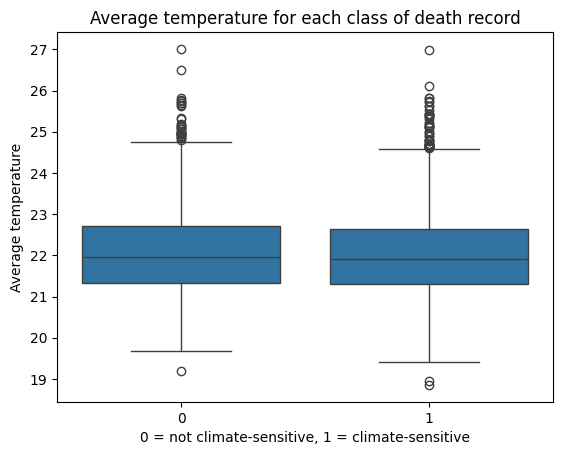

In [55]:
sns.boxplot(data=train, x="is_climate_sensitive", y="avg_temperature")
plt.title("Average temperature for each class of death record")
plt.xlabel("0 = not climate-sensitive, 1 = climate-sensitive")
plt.ylabel("Average temperature")
plt.show()

The average temperature is similar for the two classes, so temperature does not separate them.Both classes have a median near 22°C, and both have a few unusually high and low values (the dots)

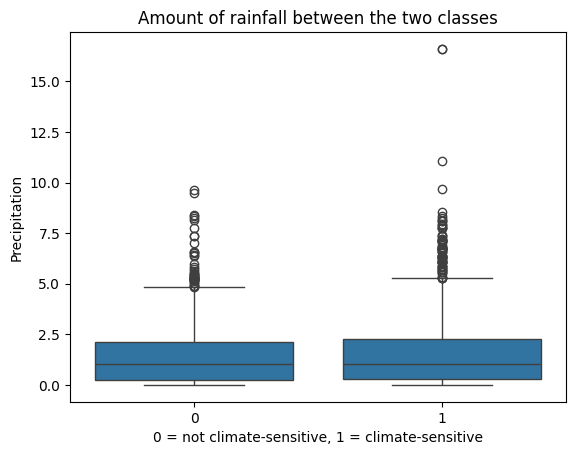

In [56]:
sns.boxplot(data=train, x="is_climate_sensitive", y="precipitation")
plt.title("Amount of rainfall between the two classes")
plt.xlabel("0 = not climate-sensitive, 1 = climate-sensitive")
plt.ylabel("Precipitation")
plt.show()

Precipitation is similar for the two classes. There are some unusually high rainfall values.

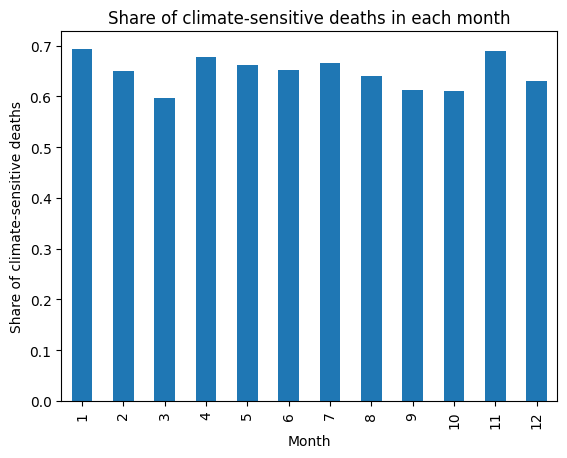

In [57]:
train["month"] = pd.to_datetime(train["deathdate"]).dt.month
train.groupby("month")["is_climate_sensitive"].mean().plot(kind="bar")
plt.title("Share of climate-sensitive deaths in each month")
plt.xlabel("Month")
plt.ylabel("Share of climate-sensitive deaths")
plt.show()

The share of climate-sensitive deaths does not change much from month to month.

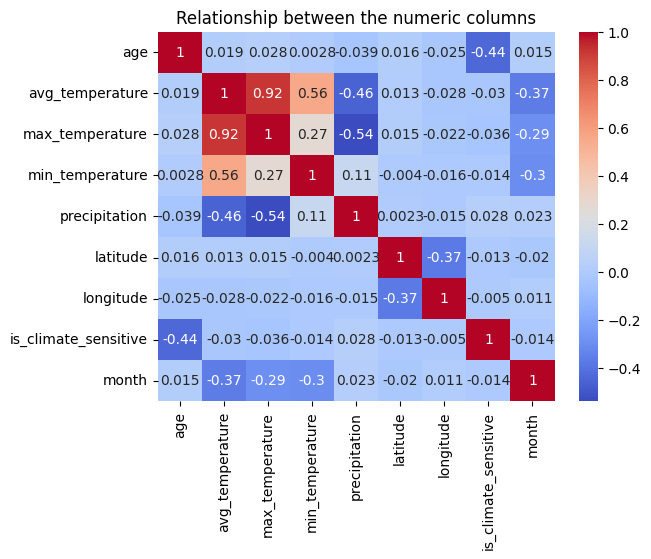

In [58]:
sns.heatmap(train.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.title("Relationship between the numeric columns")
plt.show()

The average and maximum temperature are strongly related to each other,
Age has the strongest link with the target, while the weather columns have a weak link.

# SUMMARY OF DATA VISUALISATION

##The strongest pattern in the data is Age. Zone, gender, temperature, rainfall and month show little difference between the two classes.